# RuO₂/TiO₂: five stages of complete film dissolution

This executable example follows a nominal **15 nm RuO₂ film** from a flat surface to **zero remaining Ru inventory**. Each stage pairs the native electron density with the kinematic **(00L)** and **(20L)** crystal truncation rods (CTRs).

We use the bundled `examples/CTR/RuO2_TiO2_Poisson_etching.xtal` unit cells, a **0.3 nm symmetric mixed interface**, full strain coupling, and zero interface offset. These are illustrative model choices, not a fit or a time-dependent dissolution simulation.

Only RuO₂ is removable, including its population within the mixed interface. The **complete original TiO₂ profile remains fixed**, including its interface populations and reference-subtraction terms. The final state is therefore the protected TiO₂ interface, not a newly constructed sharp substrate. No additional material is introduced.

In [1]:
%matplotlib inline
import copy
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq
from IPython.display import Markdown, display


def find_repository_root():
    """Find the checkout containing the bundled RuO2/TiO2 example."""
    relative = Path("examples/CTR/RuO2_TiO2_Poisson_etching.xtal")
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / relative).is_file():
            return candidate
    raise FileNotFoundError("Run this notebook from within the orGUI checkout.")


repository_root = find_repository_root()
sys.path.insert(0, str(repository_root))
from orgui.datautils.xrayutils import CTRcalc  # noqa: E402
from orgui.datautils.xrayutils.CTRdistributions import PoissonProfile, SkellamProfile  # noqa: E402
from orgui.datautils.xrayutils.CTRfilm import FiniteFilmBoundary, PoissonSurface  # noqa: E402

if repository_root not in Path(CTRcalc.__file__).resolve().parents:
    raise RuntimeError("Restart the kernel to use this checkout's orGUI.")

template = CTRcalc.SXRDCrystal.fromFile(
    repository_root / "examples/CTR/RuO2_TiO2_Poisson_etching.xtal"
)

## Native stack and removal law

`Film.W` counts structural layers; interface width counts lower-bulk unit cells. We convert the requested dimensions explicitly in Å. All models use 20 keV (`setEnergy` accepts **eV**).

`PoissonSurface` uses `W < 0` for etching. With `alpha = 0.15`, 15% of the parent mean removal generates Poisson roughening and the rest produces layer-by-layer progression. The three intermediate stages target **75%, 50%, and 25% remaining Ru**, using native inventory statistics to choose `W`. These fractions are material inventories, not prescribed film heights or elapsed times.

The flat initial state has `W=0`. The final state uses a deterministic shift to the native `exhausted_index`, making the remaining Ru exactly zero. Merely increasing a Poisson mean would only approach this endpoint asymptotically. Probability beyond the finite boundary is accumulated at the exhausted state by the native model; it is not discarded or conditionally renormalized.

In [2]:
film_thickness_A = 150.0
interface_width_A = 3.0
interface_tail_probability = 1e-4
roughening_fraction = 0.15
energy_eV = 20000.0
surface_name = "dissolving_surface"
film_name = "RuO2"

film_spacing_A = template[film_name].unitcell.a[2] / len(template[film_name].layers)
film_layers = int(round(film_thickness_A / film_spacing_A))
interface_width_cells = interface_width_A / template["TiO2toRuO2"].uc_bottom.a[2]


def make_model(mean_removal_layers, alpha):
    """Build a native crystal; removal is nonnegative in structural layers."""
    bulk = copy.deepcopy(template.uc_bulk)
    interface = copy.deepcopy(template["TiO2toRuO2"])
    film = copy.deepcopy(template[film_name])
    interface.profile = SkellamProfile(
        interface_width_cells,
        asymmetry=0.0,
        tail_probability=interface_tail_probability,
    )
    interface.basis[:] = [interface_width_cells, 0.0, 1.0, 0.0]
    interface.basis_0[:] = interface.basis
    film.basis[:] = film_layers
    film.basis_0[:] = film.basis
    surface = PoissonSurface(
        copy.deepcopy(film.unitcell),
        name=surface_name,
        profile=PoissonProfile(-float(mean_removal_layers), alpha, 0.0),
        boundary=FiniteFilmBoundary(films=(film_name,)),
    )
    crystal = CTRcalc.SXRDCrystal(
        bulk,
        interface,
        film,
        surface,
        stacking=np.array([1, 2, 3]),
        atten=template.atten,
    )
    crystal.setEnergy(energy_eV)
    crystal.apply_stacking()
    return crystal


def audit(crystal):
    """Return native finite-material inventories and realized surface moments."""
    return crystal.surface_height_statistics(surface=surface_name)


def remaining_ru(crystal):
    """Return remaining Ru atoms per reference lateral area."""
    return audit(crystal)["remaining_inventory"][film_name].get("Ru", 0.0)


initial = make_model(0.0, 0.0)
initial_audit = audit(initial)
initial_ru = remaining_ru(initial)
exhausted_index = initial_audit["exhausted_index"]
assert initial_ru > 0 and exhausted_index < 0
print(
    f"Nominal Film: {film_layers} layers = {film_layers * film_spacing_A / 10:.3f} nm"
)
print(
    f"Interface width: {interface_width_A / 10:.1f} nm; "
    f"exhaustion index: {exhausted_index}"
)

Nominal Film: 46 layers = 15.055 nm
Interface width: 0.3 nm; exhaustion index: -50


In [3]:
targets = np.array([1.0, 0.75, 0.50, 0.25, 0.0])
models = [initial]
removals = [0.0]
alphas = [0.0]
for target in targets[1:-1]:

    def residual(removal):
        return (
            remaining_ru(make_model(removal, roughening_fraction)) / initial_ru - target
        )

    upper = float(-exhausted_index)
    while residual(upper) > 0:
        upper *= 2.0
    removal = brentq(residual, 0.0, upper, xtol=1e-9)
    models.append(make_model(removal, roughening_fraction))
    removals.append(removal)
    alphas.append(roughening_fraction)
models.append(make_model(-exhausted_index, 0.0))
removals.append(float(-exhausted_index))
alphas.append(0.0)
stats = [audit(model) for model in models]
fractions = np.array([remaining_ru(model) / initial_ru for model in models])
np.testing.assert_allclose(fractions, targets, rtol=0, atol=1e-8)
assert remaining_ru(models[-1]) == 0.0

rows = [
    "| Stage | Ru remaining | W (layers) | alpha | "
    "Mean front (Å) | RMS front (Å) | Exhausted probability |",
    "|---|---:|---:|---:|---:|---:|---:|",
]
for number, (fraction, removal, alpha, stat) in enumerate(
    zip(fractions, removals, alphas, stats), 1
):
    rows.append(
        f"| {number} | {100 * fraction:.0f}% | {-removal:.3f} | {alpha:.2f} | "
        f"{stat['mean_front_height_A']:.3f} | {stat['rms_front_height_A']:.3f} | "
        f"{stat['exhausted_probability']:.3g} |"
    )
display(Markdown("\n".join(rows)))

| Stage | Ru remaining | W (layers) | alpha | Mean front (Å) | RMS front (Å) | Exhausted probability |
|---|---:|---:|---:|---:|---:|---:|
| 1 | 100% | -0.000 | 0.00 | 150.549 | 0.000 | 0 |
| 2 | 75% | -11.500 | 0.15 | 112.912 | 4.511 | 5.3e-40 |
| 3 | 50% | -23.000 | 0.15 | 75.274 | 6.293 | 1.1e-18 |
| 4 | 25% | -34.500 | 0.15 | 37.637 | 7.601 | 2.85e-07 |
| 5 | 0% | -50.000 | 0.00 | -13.161 | 0.000 | 1 |

## Density and corresponding CTRs

The density is the real part of native `zDensity_G(z, 0, 0)` in electrons/Å³. The blue curve is the complete protected TiO₂ density obtained from the exhausted native state. Subtracting that **same protected profile** from total density isolates remaining RuO₂; subtracting a sharp bare substrate would not.

The CTRs show **coherent kinematic intensities** `|F|²` in electrons² per reference-cell convention, with identical axes and no stage-dependent normalization. They include native bulk/film interference. No incoherent-domain mixing, DWBA, resolution convolution or experimental corrections are applied. Rough states use `|⟨F⟩|²`, not `⟨|F|²⟩`. These calculations use the existing native scattering implementation.

Reciprocal coordinates refer to the TiO₂ reference unit cell. The sampled range avoids exact integer Bragg positions.

In [4]:
z = np.linspace(-65.0, 175.0, 9601)
L = np.linspace(0.95, 7.05, 1201)
L = L[np.abs(L - np.round(L)) > 1e-6]
rods = [(0.0, 0.0), (2.0, 0.0)]

endpoint = initial.surface_height_state(surface=surface_name, index=exhausted_index)
assert endpoint.inventory[film_name] == {}
protected = endpoint.crystal
protected_density = protected.zDensity_G(z, 0, 0).real
protected_amplitudes = [protected.F(h, k, L) for h, k in rods]

densities = []
amplitudes = []
for stage, model in enumerate(models, 1):
    print(f"Evaluating stage {stage}/5")
    densities.append(model.zDensity_G(z, 0, 0).real)
    amplitudes.append([model.F(h, k, L) for h, k in rods])
densities = np.asarray(densities)
amplitudes = np.asarray(amplitudes)
ru_densities = densities - protected_density
intensities = np.abs(amplitudes) ** 2
protected_intensities = np.abs(protected_amplitudes) ** 2

Evaluating stage 1/5


Evaluating stage 2/5


Evaluating stage 3/5


Evaluating stage 4/5


Evaluating stage 5/5


## Numerical checks

Check the material endpoints, invariant protected substrate and exact complex amplitudes—not only plotted intensity. Each stage is independently rebuilt from the same initial inventory. The finite interface support retains the declared tail tolerance; “complete dissolution” means zero Ru in that represented inventory.

In [5]:
for model, stat in zip(models, stats):
    assert stat["initial_inventory"] == initial_audit["initial_inventory"]
    np.testing.assert_allclose(
        stat["added_inventory"][film_name].get("Ru", 0.0), 0.0, atol=1e-12
    )
    exhausted = model.surface_height_state(
        surface=surface_name, index=stat["exhausted_index"]
    )
    np.testing.assert_allclose(
        exhausted.crystal.zDensity_G(z, 0, 0).real,
        protected_density,
        rtol=1e-12,
        atol=1e-11,
    )
    for rod_index, (h, k) in enumerate(rods):
        np.testing.assert_allclose(
            exhausted.crystal.F(h, k, L),
            protected_amplitudes[rod_index],
            rtol=1e-12,
            atol=1e-9,
        )
nominal = initial.surface_height_state(surface=surface_name, index=0).crystal
np.testing.assert_allclose(
    densities[0], nominal.zDensity_G(z, 0, 0).real, rtol=1e-12, atol=1e-11
)
for rod_index, (h, k) in enumerate(rods):
    np.testing.assert_allclose(
        amplitudes[0, rod_index], nominal.F(h, k, L), rtol=1e-12, atol=1e-9
    )
np.testing.assert_allclose(densities[-1], protected_density, rtol=1e-12, atol=1e-11)
np.testing.assert_allclose(amplitudes[-1], protected_amplitudes, rtol=1e-12, atol=1e-9)
assert np.isfinite(densities).all() and np.isfinite(intensities).all()
assert ru_densities.min() > -1e-10
print(
    "Passed: Ru inventories, flat/full endpoints, no added Ru; "
    "invariant TiO2 density and complex amplitudes."
)

Passed: Ru inventories, flat/full endpoints, no added Ru; invariant TiO2 density and complex amplitudes.


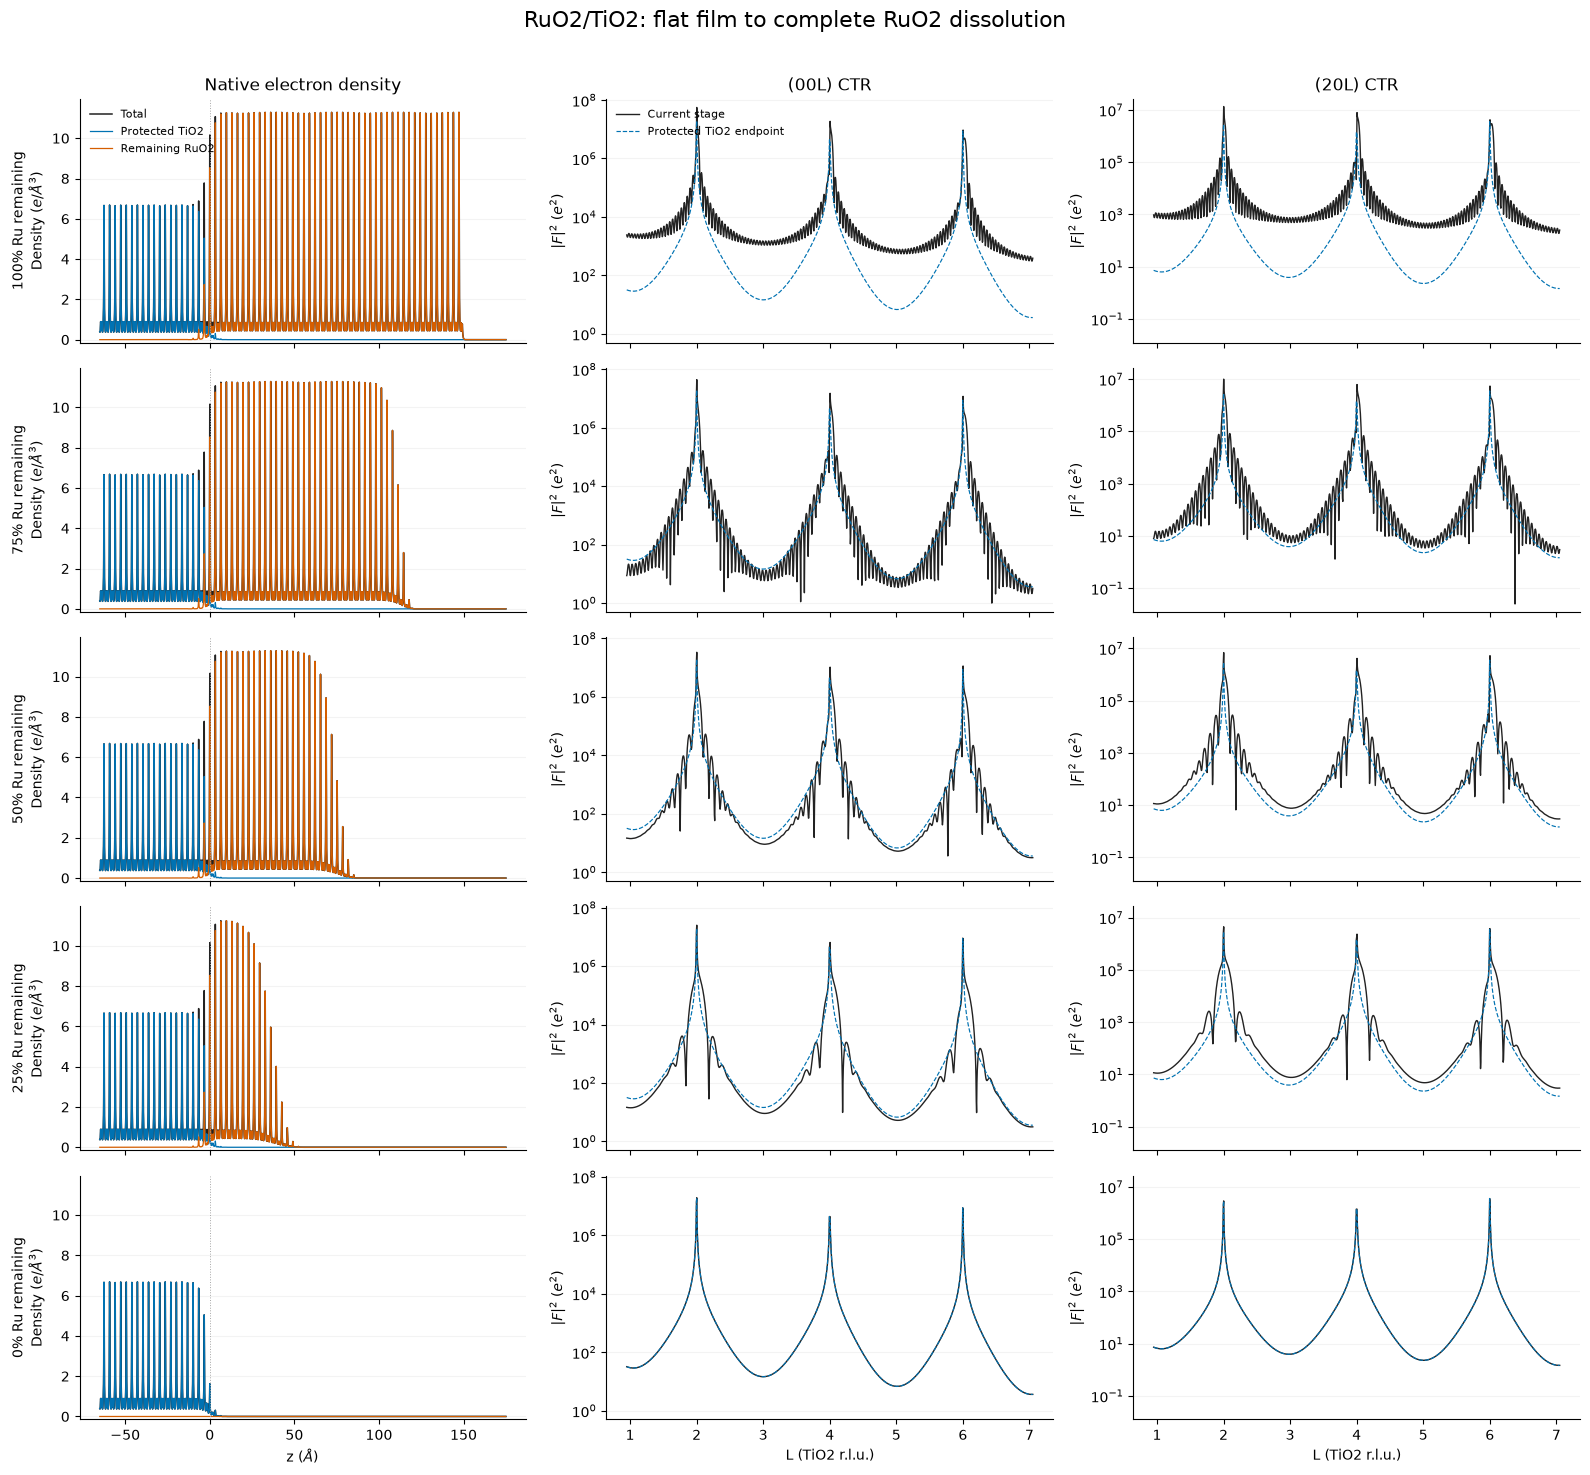

In [6]:
fig, axes = plt.subplots(5, 3, figsize=(16, 15), sharex="col", sharey="col")
colors = {"total": "#222222", "substrate": "#0072B2", "film": "#D55E00"}
for row, fraction in enumerate(fractions):
    ax = axes[row, 0]
    ax.plot(z, densities[row], color=colors["total"], lw=1.1, label="Total")
    ax.plot(
        z, protected_density, color=colors["substrate"], lw=0.9, label="Protected TiO2"
    )
    ax.plot(z, ru_densities[row], color=colors["film"], lw=0.9, label="Remaining RuO2")
    ax.set_ylabel(f"{100 * fraction:.0f}% Ru remaining\n" + r"Density ($e/\AA^3$)")
    ax.set_ylim(-0.15, 1.06 * densities.max())
    ax.axvline(0, color="0.65", ls=":", lw=0.7)
    for col in range(2):
        ctr_ax = axes[row, col + 1]
        ctr_ax.semilogy(
            L,
            intensities[row, col],
            color=colors["total"],
            lw=1.0,
            label="Current stage",
        )
        ctr_ax.semilogy(
            L,
            protected_intensities[col],
            color=colors["substrate"],
            lw=0.85,
            ls="--",
            label="Protected TiO2 endpoint",
        )
        ctr_ax.set_ylabel(r"$|F|^2$ ($e^2$)")
        positive = np.concatenate(
            [intensities[:, col].ravel(), protected_intensities[col]]
        )
        ctr_ax.set_ylim(
            max(positive[positive > 0].min() * 0.5, 1e-10), positive.max() * 2
        )
    for ax in axes[row]:
        ax.grid(axis="y", alpha=0.15)
        ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].set_title("Native electron density")
axes[0, 1].set_title("(00L) CTR")
axes[0, 2].set_title("(20L) CTR")
axes[0, 0].legend(frameon=False, fontsize=8)
axes[0, 1].legend(frameon=False, fontsize=8)
axes[-1, 0].set_xlabel(r"z ($\AA$)")
for ax in axes[-1, 1:]:
    ax.set_xlabel("L (TiO2 r.l.u.)")
fig.suptitle("RuO2/TiO2: flat film to complete RuO2 dissolution", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

The final total density and both CTRs coincide with the protected TiO₂ endpoint. Intermediate CTR changes include interference and roughness effects, so they need not scale monotonically with Ru inventory.

To explore other cases, change `roughening_fraction`, the film thickness, or interface parameters and rerun all cells. Changing substrate/interface parameters may change the protected TiO₂ structure; varying only dissolution parameters must not. Removing TiO₂ requires an explicitly modeled removable TiO₂ Film and is outside this example.

The exhausted front lies below nominal `z=0` because complete removal reaches the deepest Ru population in the finite mixed-interface support. This bookkeeping front is not a new TiO2 surface position: the protected TiO2 atoms remain where they were.